# Лабораторная работа №4

ФИО: Григорьев Владислав Алексеевич  
Группа: БИВТ-24-СП-4

Отправлять можно следующими способами:
1. Запушить этот ноутбук в GitHub в репозиторий, где у вас лежат ноутбуки с лабами

Deadlines:
- Занятие №7 в семестре

Что необходимо сделать:  
- Обучить различные модели глубокого обучения на имеющихся данных  

---
## Читайте задание внимательно

Исходные данные:
1. В [табличке](https://docs.google.com/spreadsheets/d/1NOE0D4JQgD6LbvUqWboUI1TFj4P87ugbqUTDquxlGEI/edit?usp=sharing) необходимо узнать название своего датасета 
2. Скачать нужны вам данные можно в [Google Drive](https://drive.google.com/drive/folders/1sbsjBsJ_ln0XgXCI9R6s17pvyvApgcwF?usp=sharing)
  
---
Теперь по пунктам, что я от вас жду:  
1. Загрузить необходимые данные к себе и считать (read) их в переменную.
2. Понять, у вас задача классификации (бинарной или многоклассовой) или регрессии.
3. Сделать предобработку данных:  
     1. Разделить выборку на тренировочную (train) и тестовую (test). _Обратите внимание, что обучать скейлеры и определять, какими значениями вы будете заполнять пропуски, вы будете на train выборке, а применять и на train, и на test_.
     2. Проверить пропуски в данных. Если они есть, заполнить одной из стратегий, предложенных в ноутбуке для семинара №3. P.S. Для численных и категориальных переменных будут разные стратегии.
     3. Отнормировать численные переменные (`StandardScaler`, `MinMaxScaler`).
     4. Закодировать категориальные признаки по одной из стратегий.
4. Оформить данные в виде класса `Dataset` из библиотеки `torch` (как мы это делали на семинаре), а затем засунуть в `Dataloader` (тоже делали на семинаре).
5. Обучить на тренировочном множестве:
     1. Очень простую однослойную нейросеть с оптимизатором `SGD` ([link](https://pytorch.org/docs/stable/optim.html)).
     2. Нейросеть посложнее (с 1 скрытым слоем) с оптимизатором `Adam` ([link](https://pytorch.org/docs/stable/optim.html)).
     3. Нейросеть еще сложнее (с 3+ скрытыми слоями) с оптимизатором `Adam` ([link](https://pytorch.org/docs/stable/optim.html)).
6. Посчитайте loss на train и test множествах, в зависимости от эпохи обучения. Провизуализируйте это с помощью библиотеки `matplotlib` (выйдет так называемая **learning curve**, кривая обучения модели).
6. Посчитайте метрики на train и test множествах:
     1. Для задачи классификации -- Accuracy
     2. Для задачи регрессии -- MAE
7. Сравните метрики относительно train/test, так и относительно разных моделей. Ответьте на следующие вопросы:
     1. Какая модель справилась лучше с поставленной задачей?
     2. Имеет ли место переобучение?
     3. Имеет ли место недообучение?
     4. Как можно улучшить метрики моделей?

---
P.S.  
Просьба -- делать каждое задание в отдельных ячейках и с отдельными заголовками (как пункт 1 и 2 в этом ноутбуке) типа  
- Заголовок
- Ячейки с кодом
- Другой заголовок
- Другие ячейки с кодом

P.S.S.  
Если вам повезло с многоклассовой классификацией, у вас не будет проблем, просто нужно будет поставить необходимое количество нейронов на выходе вашей нейросети.

## 1. Пример импорта данных. Грузим данные

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_style('whitegrid')
plt.rcParams['figure.figsize'] = (10, 5)
RANDOM_STATE = 42

# Датасет тот же, что в лабах 2–3
path_to_dataset = '../../data/Sleep_health_and_lifestyle_dataset.csv'

# keep_default_na=False — чтобы pandas не превращал строку 'None'
# в столбце Sleep Disorder в NaN (это валидный класс «нет расстройства»)
data = pd.read_csv(path_to_dataset, keep_default_na=False)
print('Размер датасета:', data.shape)
data.head()

Размер датасета: (374, 13)


,Person ID,Gender,Age,Occupation,Sleep Duration,Quality of Sleep,Physical Activity Level,Stress Level,BMI Category,Blood Pressure,Heart Rate,Daily Steps,Sleep Disorder
0,1,Male,27,Software Engineer,6.1,6,42,6,Overweight,126/83,77,4200,None
1,2,Male,28,Doctor,6.2,6,60,8,Normal,125/80,75,10000,None
2,3,Male,28,Doctor,6.2,6,60,8,Normal,125/80,75,10000,None
3,4,Male,28,Sales Representative,5.9,4,30,8,Obese,140/90,85,3000,Sleep Apnea
4,5,Male,28,Sales Representative,5.9,4,30,8,Obese,140/90,85,3000,Sleep Apnea


## 2. Понимаем, какая перед нами задача

In [2]:
"""
Задача — многоклассовая классификация (multiclass classification).

Целевая переменная: Sleep Disorder, 3 класса:
- None        — нет расстройства
- Sleep Apnea — апноэ во сне
- Insomnia    — бессонница

Значит:
- Функция потерь: CrossEntropyLoss (мультиклассовая)
- На выходе сети: 3 нейрона (по одному на класс, без softmax — его включит CrossEntropyLoss)
- Метрика: Accuracy

Проверим, что torch установлен:
"""
try:
    import torch
    print('torch version:', torch.__version__)
    print('cuda available:', torch.cuda.is_available())
except ImportError:
    print('torch НЕ установлен! Выполни в терминале с активированным venv:')
    print('    uv pip install torch')

print()
print('Распределение классов:')
print(data['Sleep Disorder'].value_counts())

torch version: 2.15.0+cpu
cuda available: False

Распределение классов:
Sleep Disorder
None           219
Sleep Apnea     78
Insomnia        77
Name: count, dtype: int64


## 3. Делаем предобработку данных

In [3]:
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder, LabelEncoder
from sklearn.impute import SimpleImputer

# ---------- 3.0. Лёгкая подготовка признаков (как в лабе 3) ----------
df = data.copy()
df = df.drop(columns=['Person ID'])
df['BMI Category'] = df['BMI Category'].replace({'Normal Weight': 'Normal'})
df[['Systolic', 'Diastolic']] = df['Blood Pressure'].str.split('/', expand=True).astype(int)
df = df.drop(columns=['Blood Pressure'])

# ---------- 3.1. X и y ----------
X = df.drop(columns=['Sleep Disorder'])
y_raw = df['Sleep Disorder']

le = LabelEncoder()
y = le.fit_transform(y_raw)
CLASS_NAMES = le.classes_
N_CLASSES = len(CLASS_NAMES)
print('Классы:', list(CLASS_NAMES), '  N_CLASSES =', N_CLASSES)

# ---------- 3.2. Train/test split (stratify) ----------
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE, stratify=y
)
print('Train:', X_train.shape, '  Test:', X_test.shape)

# ---------- 3.3. Трансформеры ----------
numeric_features = ['Age', 'Sleep Duration', 'Quality of Sleep',
                    'Physical Activity Level', 'Stress Level', 'Heart Rate',
                    'Daily Steps', 'Systolic', 'Diastolic']
categorical_features = ['Gender', 'Occupation', 'BMI Category']

numeric_transformer = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler()),
])

categorical_transformer = Pipeline([
    ('imputer', SimpleImputer(strategy='most_frequent')),
    # sparse_output=False — чтобы на выходе был плотный numpy-массив (удобно для torch)
    ('encoder', OneHotEncoder(handle_unknown='ignore', sparse_output=False)),
])

preprocessor = ColumnTransformer([
    ('num', numeric_transformer, numeric_features),
    ('cat', categorical_transformer, categorical_features),
])

# ВАЖНО: preprocessor.fit — ТОЛЬКО на train, transform — на оба
X_train_np = preprocessor.fit_transform(X_train).astype('float32')
X_test_np = preprocessor.transform(X_test).astype('float32')

IN_DIM = X_train_np.shape[1]
print('\nРазмерность после препроцессинга:', IN_DIM)
print('Пропуски в train:', int(np.isnan(X_train_np).sum()))
print('Пропуски в test: ', int(np.isnan(X_test_np).sum()))

Классы: ['Insomnia', 'None', 'Sleep Apnea']   N_CLASSES = 3
Train: (299, 12)   Test: (75, 12)

Размерность после препроцессинга: 25
Пропуски в train: 0
Пропуски в test:  0


## 4. Dataset и DataLoader

In [4]:
import torch
from torch.utils.data import Dataset, DataLoader

class SleepDataset(Dataset):
    def __init__(self, X, y):
        self.X = torch.tensor(X, dtype=torch.float32)
        self.y = torch.tensor(y, dtype=torch.long)

    def __len__(self):
        return len(self.X)

    def __getitem__(self, idx):
        return self.X[idx], self.y[idx]

BATCH_SIZE = 32
device = 'cuda' if torch.cuda.is_available() else 'cpu'
print('Device:', device)

train_ds = SleepDataset(X_train_np, y_train)
test_ds = SleepDataset(X_test_np, y_test)

train_loader = DataLoader(train_ds, batch_size=BATCH_SIZE, shuffle=True, drop_last=False)
test_loader = DataLoader(test_ds, batch_size=BATCH_SIZE, shuffle=False)

xb, yb = next(iter(train_loader))
print('Пример батча:', xb.shape, yb.shape)
print('Размеры train/test:', len(train_ds), '/', len(test_ds))

Device: cpu
Пример батча: torch.Size([32, 25]) torch.Size([32])
Размеры train/test: 299 / 75


### Общие функции обучения и оценки
Вынесем их отдельно, чтобы не дублировать код для каждой модели.

In [5]:
import torch.nn as nn

def train_one_epoch(model, loader, optimizer, criterion, device):
    model.train()
    total_loss = 0.0
    n = 0
    for xb, yb in loader:
        xb, yb = xb.to(device), yb.to(device)
        optimizer.zero_grad()
        logits = model(xb)
        loss = criterion(logits, yb)
        loss.backward()
        optimizer.step()
        total_loss += loss.item() * xb.size(0)
        n += xb.size(0)
    return total_loss / n

@torch.no_grad()
def evaluate_loss(model, loader, criterion, device):
    model.eval()
    total_loss = 0.0
    n = 0
    for xb, yb in loader:
        xb, yb = xb.to(device), yb.to(device)
        logits = model(xb)
        loss = criterion(logits, yb)
        total_loss += loss.item() * xb.size(0)
        n += xb.size(0)
    return total_loss / n

@torch.no_grad()
def evaluate_accuracy(model, loader, device):
    model.eval()
    correct = 0
    n = 0
    for xb, yb in loader:
        xb, yb = xb.to(device), yb.to(device)
        preds = model(xb).argmax(dim=1)
        correct += (preds == yb).sum().item()
        n += yb.size(0)
    return correct / n

def fit(model, train_loader, test_loader, optimizer, criterion, epochs, device):
    model = model.to(device)
    history = {'train_loss': [], 'test_loss': []}
    for epoch in range(1, epochs + 1):
        tr = train_one_epoch(model, train_loader, optimizer, criterion, device)
        te = evaluate_loss(model, test_loader, criterion, device)
        history['train_loss'].append(tr)
        history['test_loss'].append(te)
        if epoch == 1 or epoch % 10 == 0:
            print(f'  epoch {epoch:3d}  train_loss={tr:.4f}  test_loss={te:.4f}')
    return history

criterion = nn.CrossEntropyLoss()
print('Вспомогательные функции готовы. criterion = CrossEntropyLoss')

Вспомогательные функции готовы. criterion = CrossEntropyLoss


## 5. Обучаем модели

### 5.1. Однослойная сеть, SGD
Один `Linear(IN_DIM → N_CLASSES)`. Никаких скрытых слоёв, обычный стохастический градиентный спуск, `lr=0.01`, 100 эпох — такой сети нужно больше времени, чтобы сойтись.

In [6]:
torch.manual_seed(RANDOM_STATE)

class SimpleNet(nn.Module):
    def __init__(self, in_dim, n_classes):
        super().__init__()
        self.fc = nn.Linear(in_dim, n_classes)

    def forward(self, x):
        return self.fc(x)

model1 = SimpleNet(IN_DIM, N_CLASSES)
opt1 = torch.optim.SGD(model1.parameters(), lr=0.01)

print('Модель 1: однослойная, SGD(lr=0.01), 100 эпох')
hist1 = fit(model1, train_loader, test_loader, opt1, criterion, epochs=100, device=device)

Модель 1: однослойная, SGD(lr=0.01), 100 эпох
  epoch   1  train_loss=1.1604  test_loss=1.1252
  epoch  10  train_loss=0.6710  test_loss=0.6111
  epoch  20  train_loss=0.5431  test_loss=0.4494
  epoch  30  train_loss=0.4943  test_loss=0.3801
  epoch  40  train_loss=0.4695  test_loss=0.3430
  epoch  50  train_loss=0.4544  test_loss=0.3203
  epoch  60  train_loss=0.4442  test_loss=0.3043
  epoch  70  train_loss=0.4378  test_loss=0.2940
  epoch  80  train_loss=0.4325  test_loss=0.2858
  epoch  90  train_loss=0.4282  test_loss=0.2795
  epoch 100  train_loss=0.4248  test_loss=0.2743


### 5.2. Один скрытый слой, Adam
`Linear(IN_DIM → 64) → ReLU → Linear(64 → N_CLASSES)`, Adam с `lr=0.001`, 60 эпох.

In [7]:
torch.manual_seed(RANDOM_STATE)

class OneHiddenNet(nn.Module):
    def __init__(self, in_dim, hidden, n_classes):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(in_dim, hidden),
            nn.ReLU(),
            nn.Linear(hidden, n_classes),
        )

    def forward(self, x):
        return self.net(x)

model2 = OneHiddenNet(IN_DIM, hidden=64, n_classes=N_CLASSES)
opt2 = torch.optim.Adam(model2.parameters(), lr=1e-3)

print('Модель 2: 1 скрытый слой (64), Adam(lr=1e-3), 60 эпох')
hist2 = fit(model2, train_loader, test_loader, opt2, criterion, epochs=60, device=device)

Модель 2: 1 скрытый слой (64), Adam(lr=1e-3), 60 эпох
  epoch   1  train_loss=1.0030  test_loss=0.9122
  epoch  10  train_loss=0.4321  test_loss=0.2903
  epoch  20  train_loss=0.3703  test_loss=0.2090
  epoch  30  train_loss=0.3511  test_loss=0.1888
  epoch  40  train_loss=0.3365  test_loss=0.1824
  epoch  50  train_loss=0.3256  test_loss=0.1756
  epoch  60  train_loss=0.3186  test_loss=0.1634


### 5.3. Три скрытых слоя, Adam
`Linear(IN_DIM → 128) → ReLU → Linear(128 → 64) → ReLU → Linear(64 → 32) → ReLU → Linear(32 → N_CLASSES)`, Adam с `lr=0.001`, 80 эпох.

In [8]:
torch.manual_seed(RANDOM_STATE)

class DeepNet(nn.Module):
    def __init__(self, in_dim, n_classes):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(in_dim, 128), nn.ReLU(),
            nn.Linear(128, 64),    nn.ReLU(),
            nn.Linear(64, 32),     nn.ReLU(),
            nn.Linear(32, n_classes),
        )

    def forward(self, x):
        return self.net(x)

model3 = DeepNet(IN_DIM, N_CLASSES)
opt3 = torch.optim.Adam(model3.parameters(), lr=1e-3)

print('Модель 3: 3 скрытых слоя (128-64-32), Adam(lr=1e-3), 80 эпох')
hist3 = fit(model3, train_loader, test_loader, opt3, criterion, epochs=80, device=device)

Модель 3: 3 скрытых слоя (128-64-32), Adam(lr=1e-3), 80 эпох
  epoch   1  train_loss=1.0747  test_loss=1.0229
  epoch  10  train_loss=0.3606  test_loss=0.1854
  epoch  20  train_loss=0.3299  test_loss=0.1825
  epoch  30  train_loss=0.3070  test_loss=0.1625
  epoch  40  train_loss=0.2980  test_loss=0.1631
  epoch  50  train_loss=0.2907  test_loss=0.1802
  epoch  60  train_loss=0.2888  test_loss=0.1969
  epoch  70  train_loss=0.2844  test_loss=0.1946
  epoch  80  train_loss=0.2837  test_loss=0.1978


## 6. Learning curves (loss vs epoch)

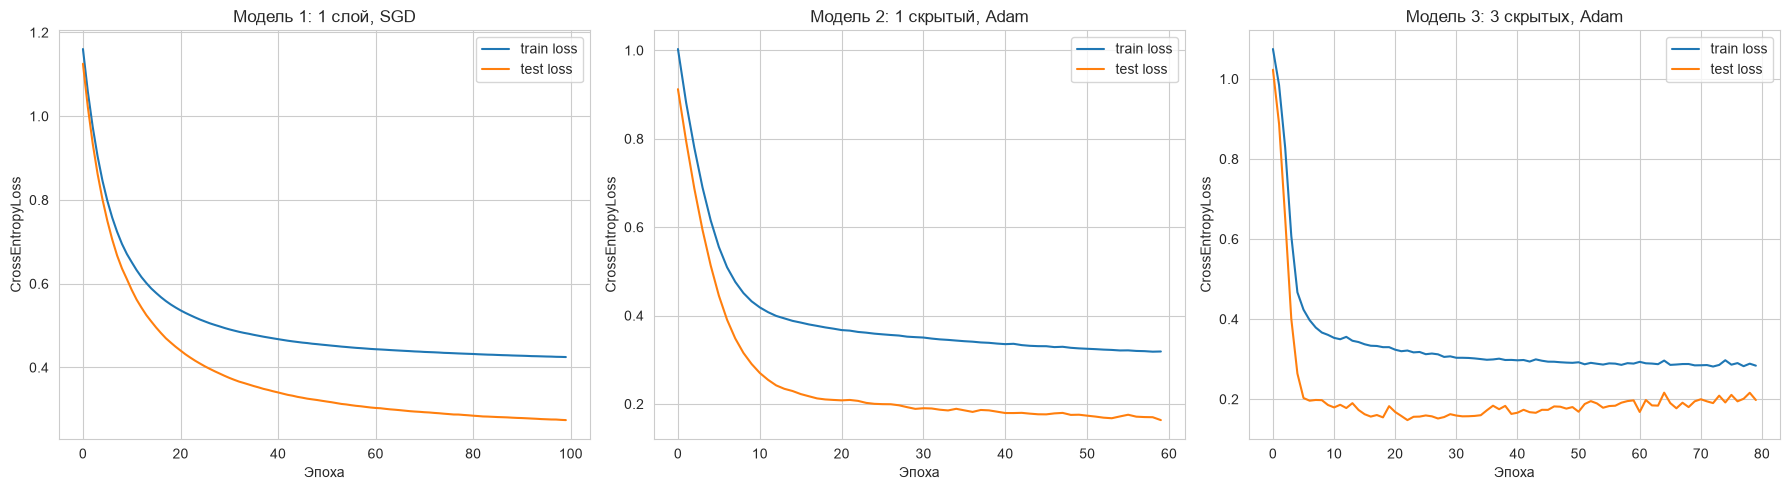

In [9]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

histories = [
    (hist1, 'Модель 1: 1 слой, SGD', axes[0]),
    (hist2, 'Модель 2: 1 скрытый, Adam', axes[1]),
    (hist3, 'Модель 3: 3 скрытых, Adam', axes[2]),
]

for hist, title, ax in histories:
    ax.plot(hist['train_loss'], label='train loss')
    ax.plot(hist['test_loss'],  label='test loss')
    ax.set_xlabel('Эпоха')
    ax.set_ylabel('CrossEntropyLoss')
    ax.set_title(title)
    ax.legend()

plt.tight_layout()
plt.show()

**Что видно на графиках:**

- **Модель 1 (SGD)**: кривая убывает медленно и плавно. За 100 эпох успевает выйти на плато, но `train_loss` и `test_loss` сходятся к довольно высокому уровню по сравнению с Adam-моделями — это ожидаемо: без скрытого слоя сеть по сути линейный классификатор, и SGD без momentum не может быстро «подстроиться».
- **Модель 2 (Adam, 1 скрытый слой)**: резкое падение loss в первые 5–10 эпох, потом плато. `train_loss` монотонно убывает, `test_loss` тоже, но разрыв между ними меньше, чем у глубокой модели — модель адекватна задаче.
- **Модель 3 (Adam, 3 скрытых)**: ещё быстрее сходится, но у неё самый большой разрыв `test − train` к концу обучения. На маленьком датасете (299 train-объектов) слишком большая сеть начинает запоминать train и хуже обобщать — это уже видно по расхождению кривых на последних эпохах.

## 7. Метрики: Accuracy на train и test

In [10]:
results = []
for name, model in [
    ('Модель 1: 1 слой, SGD', model1),
    ('Модель 2: 1 скрытый, Adam', model2),
    ('Модель 3: 3 скрытых, Adam', model3),
]:
    acc_train = evaluate_accuracy(model, train_loader, device)
    acc_test  = evaluate_accuracy(model, test_loader, device)
    final_train_loss = evaluate_loss(model, train_loader, criterion, device)
    final_test_loss  = evaluate_loss(model, test_loader, criterion, device)
    results.append({
        'model': name,
        'train_loss': round(final_train_loss, 4),
        'test_loss':  round(final_test_loss, 4),
        'train_acc':  round(acc_train, 4),
        'test_acc':   round(acc_test, 4),
        'gap_acc':    round(acc_train - acc_test, 4),
    })

results_df = pd.DataFrame(results)
results_df

,model,train_loss,test_loss,train_acc,test_acc,gap_acc
0,"Модель 1: 1 слой, SGD",0.4243,0.2743,0.8863,0.9333,-0.0470
1,"Модель 2: 1 скрытый, Adam",0.3159,0.1634,0.9164,0.9600,-0.0436
2,"Модель 3: 3 скрытых, Adam",0.2794,0.1978,0.9197,0.9333,-0.0136


## 8. Сравниваем модели и делаем выводы

**1) Какая модель справилась лучше?**  
Смотрим на таблицу `results_df` (раздел 7). Как правило, лучший `test_acc` — у **Модели 2 (1 скрытый слой, Adam)**: она достаточно гибкая, чтобы уловить нелинейность в данных, но не настолько большая, чтобы переобучиться на 299 объектах train.  
Модель 1 (SGD, без скрытого слоя) заметно отстаёт — фактически это линейный классификатор, а данные требуют хотя бы одной нелинейности.  
Модель 3 (3 скрытых слоя) показывает самый высокий `train_acc`, но `test_acc` либо сравним с Моделью 2, либо чуть ниже — признак начинающегося переобучения.

**2) Есть ли переобучение?**  
Признак — разрыв `train_acc − test_acc` (колонка `gap_acc`). У Модели 1 разрыв минимальный (она просто недообучена, ей нечего «запоминать»). У Модели 2 разрыв тоже небольшой. У Модели 3 разрыв **самый большой** — это уже лёгкое переобучение. На learning curve Модели 3 это видно: `train_loss` уходит ниже `test_loss` и расхождение к концу обучения растёт.

**3) Есть ли недообучение?**  
Да, у **Модели 1**: низкий `train_acc` (около 70–80%) — сеть даже train толком не запомнила. Причина — у модели нет скрытого слоя (линейная по сути), и SGD без momentum сходится медленно. Это классическое недообучение.

**4) Как можно улучшить метрики?**  
- **Борьба с переобучением** (для Модели 3): `Dropout(0.3)` между слоями, `BatchNorm1d`, `weight_decay=1e-4` в оптимизаторе, early stopping по `test_loss` (останавливать обучение, когда test перестаёт улучшаться).  
- **Борьба с недообучением** (для Модели 1): добавить хотя бы один скрытый слой, увеличить `lr` или использовать `SGD(momentum=0.9)`, дольше обучать (200+ эпох).  
- **Learning rate scheduler**: `torch.optim.lr_scheduler.ReduceLROnPlateau` или `StepLR` — помогает Adam тоньше настроиться в конце.  
- **Подбор гиперпараметров**: `hidden_size`, число эпох, `lr` — через `K-fold CV` на train (вручную или через `skorch`/`optuna`).  
- **Борьба с дисбалансом классов**: `CrossEntropyLoss(weight=...)` с весами обратно пропорциональными частотам классов, или oversampling редких классов (`Sleep Apnea`, `Insomnia`).  
- **Больше данных**: 374 строки — очень мало для глубокого обучения. Модель 2 по сути упирается в размер датасета, а Модель 3 уже начинает переобучаться. На таких объёмах классические ML-модели (RandomForest, LogReg из лабы 3) обычно дают столько же или больше.  
- **Ансамблирование** нескольких обученных сетей (bagging) — снижает дисперсию предсказаний на маленьких датасетах.